# Train RSGM on every 30th frame of AMASS



RSGM, the Riemannian score-based generative model on SO(3)^19 (`hp/models/rsgm.py`), trained on the same data as the HuProSO3 flow `prior_c30/id_9030` of `train_priors_strides.ipynb`, so that `rsgm_huproso_comparison.ipynb` can compare the two:
- **data:** every 30th frame of our local AMASS (`~/data/AMASS_rotations_c30`), the official train / valid split (`ORIGINAL_AMASS_SPLITS`);
- **model and training:** `config/models/rsgm.yaml`, the settings of the SO(3) experiment of riemannian-score-sde (5 x 512 sin MLP, Adam 2e-4, batch 512, EMA 0.999, 100k iterations), except **β_f = 10** instead of 6: the likelihood takes the end of the noising as uniform, and with 10 that costs ~3e-4 nats per joint instead of ~0.01;
- **device:** mps, 1.8-2x faster than cpu for training at batch 512 (`scripts/benchmark_rsgm.py`).

The validation loss is the denoising loss of the EMA weights on the compressed valid split, with fixed times and noise, so validations are comparable with each other. The likelihood and the comparison with the flow are in `rsgm_huproso_comparison.ipynb`.

A finished run (a `run_*` folder with `history.json`) is not trained again; `RETRAIN = True` trains a new one (runs are never overwritten).

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from omegaconf import OmegaConf

from hp.data.amass_cfg import ORIGINAL_AMASS_SPLITS
from hp.evaluation.data import load_reference
from hp.models.io import load_model
from hp.training import cli
from hp.training.config import load_config

# ---- parameters ----------------------------------------------------------------------
ROTATIONS = "~/data/AMASS_rotations"        # all frames (needs "data.load_dtype=float32" in OVERRIDES)
#ROTATIONS = "~/data/AMASS_rotations_c30"   # every 30th frame: the data the hyperparameters were tuned on
SPLIT = "original"                          # the official AMASS split, as for the flow prior_c30/id_9030
RUN_ROOT = "~/data/experiments"             # runs go to RUN_ROOT/RUN_NAME/run_0001, run_0002, ...
RUN_NAME = "rsgm_tuned_r2t12"
#RUN_NAME = "rsgm_tuned_t23"
#RUN_NAME = "rsgm_c30_tuned_t23"
#RUN_NAME = "rsgm_cosine_warmup"
#RUN_NAME = "rsgm_c30"
DEVICE = "mps"                              # "cpu", "mps" or "cuda:0"
SEED = 10
RETRAIN = False                             # True: train a new run even if a finished one exists
# the best trial of round 2 of rsgm-hyperparameter-tuning.ipynb (study rsgm_c30_round2): trial 12, validation
# log-likelihood 138.29 after 30k steps (round 1 best: 138.08, the default configuration: 131.74), tuned on every 30th
# frame; here on all frames, at the full budget of config/models/rsgm.yaml (100k steps). 4.4M parameters, ~30 min on mps.
# beta_f = 6 is the low end of what works (4.4 and 5.0 were pruned); the end of the noising is then not quite uniform
# (likelihood ~0.2 nats too low). Within the noise of it: round-2 trial 21 (beta_f 6.97, lr 1.06e-3, 138.16).
TUNED = ["model.args.hidden=[1024, 1024, 1024, 1024, 1024]", "model.args.activation=silu", "model.args.beta_f=6.001785882190684",
         "model.args.loss_t_min=0.0014132242507652467", "model.args.weighting=std",
         "train.lr=0.0016037019000311485", "train.batch_size=512", "train.ema_decay=0.999", "train.scheduler=step"]
# round 1, trial 23 (validation 137.34 after 30k steps; on the test: 138.16, run rsgm_tuned_t23):
#TUNED = ["model.args.hidden=[1024, 1024, 1024]", "model.args.activation=silu", "model.args.beta_f=8.989556539013165",
#         "model.args.loss_t_min=0.0030728873202715665", "model.args.weighting=std",
#         "train.lr=0.0010569766304589611", "train.batch_size=512", "train.ema_decay=0.999", "train.scheduler=step"]
OVERRIDES = ["data.load_dtype=float32", "train.valid_interval=5000", *TUNED]
#OVERRIDES = ["data.load_dtype=float32", "train.valid_interval=5000", "train.scheduler=cosine", "train.warmup_steps=500"]
#OVERRIDES = ["data.load_dtype=float32", "train.valid_interval=5000"]
N_CHECK = 500                               # valid poses for the quick likelihood check at the end
# ----------------------------------------------------------------------------------------

expand = lambda p: Path(p).expanduser()
argv = ["model=rsgm", f"run_root={RUN_ROOT}", f"run_name={RUN_NAME}", f"seed={SEED}", f"data.rotations={ROTATIONS}",
        f"data.split={SPLIT}", f"train.device={DEVICE}", *OVERRIDES]
cfg = load_config(argv)
print(OmegaConf.to_yaml(cfg))

train_frames = sum(torch.load(expand(ROTATIONS) / f"{d}.pt", mmap=True).shape[0] for d in ORIGINAL_AMASS_SPLITS["train"])
iterations, batch = cfg.train.max_iterations, cfg.train.batch_size
print(f"{iterations:,} iterations x batch {batch} = {iterations * batch / train_frames:.1f} epochs over {train_frames:,} training frames")

run_name: rsgm_tuned_r2t12
run_root: ~/data/experiments
seed: 10
tensorboard: true
data:
  rotations: ~/data/AMASS_rotations
  split: original
  load_dtype: float32
train:
  max_iterations: 100000
  batch_size: 512
  lr: 0.0016037019000311485
  scheduler: step
  lr_step_fraction: 0.7
  lr_gamma: 0.5
  warmup_steps: 0
  clip_grad_norm: 1.0
  ema_decay: 0.999
  valid_interval: 5000
  checkpoint_every: 10000
  device: mps
  num_workers: 0
  progress: true
model:
  name: rsgm
  args:
    hidden:
    - 1024
    - 1024
    - 1024
    - 1024
    - 1024
    activation: silu
    beta_0: 0.001
    beta_f: 6.001785882190684
    eps: 0.0002
    loss_t_min: 0.0014132242507652467
    sample_steps: 100
    likelihood_steps: 100
    weighting: std

100,000 iterations x batch 512 = 3.5 epochs over 14,779,964 training frames


## Train

With `scripts/train_model.py` (`hp.training.cli.main`). The wall time is stored in `train_time.json` of the run folder, for the comparison of the training budgets.

In [3]:
def finished_run(root):
    # The newest run folder below root that finished (has history.json and weights.pt), or None.
    runs = sorted(p for p in root.glob("run_[0-9][0-9][0-9][0-9]") if (p / "history.json").is_file() and (p / "weights.pt").is_file())
    return runs[-1] if runs else None


run_dir = None if RETRAIN else finished_run(expand(RUN_ROOT) / RUN_NAME)
if run_dir is not None:
    print(f"already trained: {run_dir}")
else:
    start = time.perf_counter()
    run_dir = cli.main(argv)
    seconds = time.perf_counter() - start
    (run_dir / "train_time.json").write_text(json.dumps({"seconds": seconds, "device": DEVICE}))
    print(f"trained in {seconds / 60:.1f} min")

INFO:root:Using the following datasets of AMASS: ['CMU', 'PosePrior', 'TotalCapture', 'EyesJapanDataset', 'KIT', 'BMLrub', 'EKUT', 'TCDHands', 'ACCAD'].
INFO:root:Datasets ['CMU', 'PosePrior', 'TotalCapture', 'EyesJapanDataset', 'KIT', 'BMLrub', 'EKUT', 'TCDHands', 'ACCAD'] loaded. Number of samples: 14779964
INFO:root:Using the following datasets of AMASS: ['HumanEva', 'HDM05', 'SFU', 'MoSh'].
INFO:root:Datasets ['HumanEva', 'HDM05', 'SFU', 'MoSh'] loaded. Number of samples: 1320126


Training rsgm (4,433,977 parameters) on mps; run folder /Users/evgeniifedorov/data/experiments/rsgm_tuned_r2t12/run_0001


100%|██████████| 100000/100000 [32:46<00:00, 50.84it/s]


Saved to /Users/evgeniifedorov/data/experiments/rsgm_tuned_r2t12/run_0001
trained in 33.3 min


## Loss curves


Training loss of every step (and its moving average) and the validation loss. Epochs over the training frames on the top axis.

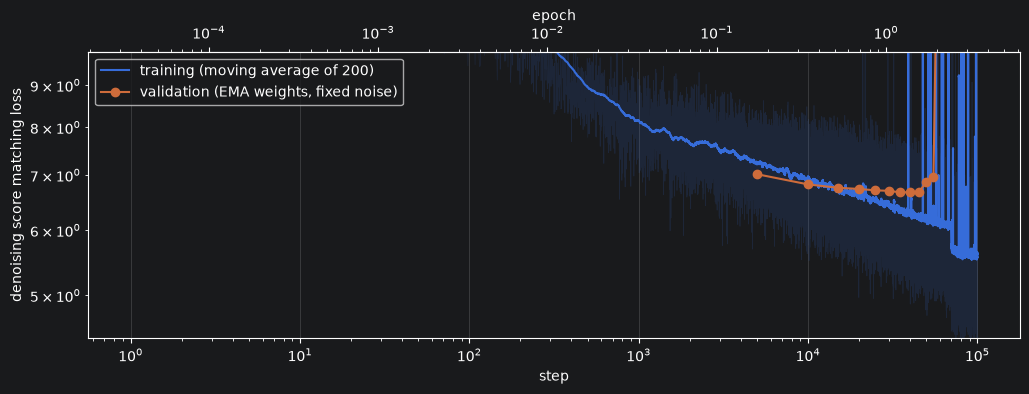

validation loss: last 3254.994, best 6.668 at step 35,000


In [4]:
SMOOTH = 200  # steps of the moving average

history = json.loads((run_dir / "history.json").read_text())
loss = np.asarray(history["loss"], dtype=float)
steps = np.arange(1, len(loss) + 1)
smooth = np.convolve(loss, np.ones(SMOOTH) / SMOOTH, mode="valid")
per_epoch = train_frames / batch  # steps per epoch

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(steps, loss, color="C0", alpha=0.15, lw=0.5)
ax.plot(steps[SMOOTH - 1:], smooth, color="C0", label=f"training (moving average of {SMOOTH})")
ax.plot(history["valid_iteration"], history["valid_loss"], "o-", color="C1", label="validation (EMA weights, fixed noise)")
ax.set_ylim(np.percentile(loss, 1) * 0.9, np.percentile(loss, 99.5) * 1.1)
ax.set_xlabel("step")
ax.set_ylabel("denoising score matching loss")
ax.secondary_xaxis("top", functions=(lambda s: s / per_epoch, lambda e: e * per_epoch)).set_xlabel("epoch")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.loglog()
plt.show()

if history["valid_loss"]:
    best = int(np.argmin(history["valid_loss"]))
    print(f"validation loss: last {history['valid_loss'][-1]:.3f}, best {history['valid_loss'][best]:.3f} at step {history['valid_iteration'][best]:,}")

## Quick check
The EMA weights: samples must be valid rotations, and the log-likelihood of `N_CHECK` poses of the compressed valid split (probability flow ODE, about 8 ms per pose on mps) must be finite. The full evaluation is in `rsgm_huproso_comparison.ipynb`.

In [5]:
model = load_model(run_dir, device=DEVICE, weights="weights_ema")
torch.manual_seed(SEED)
samples = model.sample(1000).cpu().double()
eye = torch.eye(3, dtype=torch.float64)
print(f"samples: {tuple(samples.shape)}, max |R^T R - I| = {(samples.transpose(-1, -2) @ samples - eye).abs().max():.1e}, "
      f"min det = {torch.linalg.det(samples).min():.4f}")

valid = load_reference("valid", ROTATIONS, SPLIT)
poses = valid[torch.randperm(len(valid), generator=torch.Generator().manual_seed(SEED))[:N_CHECK]]
start = time.perf_counter()
with torch.no_grad():
    ll = torch.cat([model.log_prob(poses[i:i + 250].to(model.device)).cpu() for i in range(0, len(poses), 250)])
print(f"log-likelihood of {len(poses)} valid poses: {ll.mean():.2f} +- {ll.std() / len(ll) ** 0.5:.2f} (s.e.m.), "
      f"{(~torch.isfinite(ll)).sum()} non-finite, {(time.perf_counter() - start) / len(poses) * 1000:.1f} ms per pose")

INFO:root:Using the following datasets of AMASS: ['HumanEva', 'HDM05', 'SFU', 'MoSh'].


samples: (1000, 19, 3, 3), max |R^T R - I| = 3.8e-06, min det = 1.0000


INFO:root:Datasets ['HumanEva', 'HDM05', 'SFU', 'MoSh'] loaded. Number of samples: 1320126


log-likelihood of 500 valid poses: 136.75 +- 0.72 (s.e.m.), 0 non-finite, 19.0 ms per pose
